# 39 · 대조학습과 InfoNCE

📎 **이번 질문** · 같은 과일의 두 사진을 배치 속에서 짝지으면 무엇을 배울까요?

준비물: 08 attention의 점수표, 12 확률·CE, [38 변형](38_augmentations.ipynb), 03·04의 미분·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 과일의 상태와 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 정규화한 표현의 내적으로 점수표를 만들고 자기 자신을 분모에서 뺍니다.
2. 양쪽 뷰가 같은 표현기를 쓰므로 점수표의 두 경로와 정규화 미분을 모두 더합니다.
3. 라벨 없는 목적값과 고정 표현의 독립 선형 평가를 분리합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/contrastive_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.contrastive_plots import plot_panels,plot_curves,plot_points
setup_plots()

'Arial Unicode MS'

## 🔑 1. 길이를 줄이고 방향을 비교합니다

**이 절에서 가져갈 것:** 표현의 방향을 비교하려면 정규화의 축과 영벡터 규약이 필요합니다.

과일 상태와 촬영 배경 네 숫자 $X:(N,4)$를 표현기 $f_\theta$에 넣어 $Z:(N,D)$를 만듭니다. 특징의 크기만 키워 점수를 높이는 효과를 줄이기 위해 행마다 정규화합니다.

> **용어**
> - **표현 또는 embedding**은 모델이 입력에서 계산한 숫자 벡터입니다.
> - **대조학습(contrastive learning)**은 지정한 쌍의 상대적 점수가 다른 후보보다 높아지도록 학습하는 방법입니다.
> - **유사도(similarity)**는 여기서 정규화한 두 행의 내적입니다.

$$r_i=\sqrt{\sum_d Z_{id}^2+\epsilon},\quad U_i=Z_i/r_i,\quad C_{ij}=U_i^TU_j.$$

$\epsilon=10^{-8}$을 둡니다. 영벡터의 U는0이고 미분은 유한합니다. 따라서 정확한 단위 길이가 아니라 **평활화한 정규화**이며 nonzero 크기가 충분할 때 cosine에 가깝습니다. $C:(N,N)$의 행 i와 열 j가 비교할 관측입니다.

> **코드** · `keepdims=True`는 합친 축을 길이1로 남겨 (N,1)을 만듭니다. `U@U.T`는 모든 행 쌍 내적입니다. `np.eye(N)`은 대각선만1인 표입니다.

In [2]:
vectors=np.array([[3.,4.],[0.,5.],[0.,0.]])
radii=np.sqrt((vectors**2).sum(axis=1,keepdims=True)+1e-8)
unit=vectors/radii
similarity=unit@unit.T

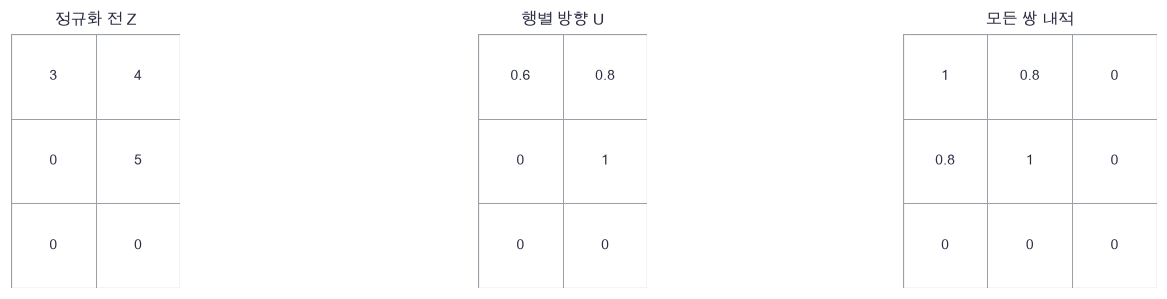

In [3]:
plot_panels([vectors,unit,similarity],['정규화 전 Z','행별 방향 U','모든 쌍 내적'])

🔍 **확인** · (3,4)는 약(.6,.8)이 되어 (0,1)과 내적.8입니다. 영벡터는 방향 정보가 없으며 어느 행과도 내적0입니다.

In [4]:
def normalize_rows(H,eps=1e-8):
    """평활화한 행 정규화. H:(N,D) → U=H/sqrt(sum(H²)+eps), r:(N,1)."""
    r=np.sqrt((H**2).sum(axis=1,keepdims=True)+eps)
    return H/r,r

In [5]:
def similarity_loop(U):
    """행 사이 내적을 세 반복문으로 계산합니다. U:(N,D) → (N,N)."""
    S=np.zeros((len(U),len(U)))
    for i in range(len(U)):
        for j in range(len(U)):
            for k in range(U.shape[1]):
                S[i,j]+=U[i,k]*U[j,k]
    return S

In [6]:
# 쓰는 것: vectors (1절)
actual,_=normalize_rows(vectors)
np.testing.assert_allclose(actual,[[.6,.8],[0.,1.],[0.,0.]],atol=1e-8)  # 검산: 손계산 방향
np.testing.assert_allclose(similarity_loop(actual),actual@actual.T)  # 검산: 반복문 = 벡터화
assert np.isfinite(actual).all(), '영벡터 정규화도 유한해야 합니다'
print('손계산·반복문·벡터화와 영벡터 규약이 일치합니다.')

손계산·반복문·벡터화와 영벡터 규약이 일치합니다.


### ✏️ 연습 1 · 정규화할 축을 고르기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

Z:(N,D)의 행별 Euclidean 길이를 (N,1)로 계산하세요. 이 연습은 epsilon 전 길이입니다.

In [7]:
def exercise_row_norm(Z):
    """Z:(N,D)의 행별 Euclidean 길이를 (N,1)로 계산하세요. 이 연습은 epsilon 전 길이입니다."""

    ### 구현할 내용: Z:(N,D)의 행별 Euclidean 길이를 (N,1)로 계산하세요. 이 연습은 epsilon 전 길이입니다.
    raise NotImplementedError
    return r

In [8]:
def check_row_norm(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[3.,4.],[5.,12.],[0.,0.]])),[[5.],[13.],[0.]])  # 검산: 각 관측의 길이
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_row_norm,exercise_row_norm,hint="Z:(N,D)의 행별 Euclidean 길이를 (N,1)로 계산하세요. 이 연습은 epsilon 전 길이입니다.")

☐ exercise_row_norm: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: Z:(N,D)의 행별 Euclidean 길이를 (N,1)로 계산하세요. 이 연습은 epsilon 전 길이입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
r = np.sqrt((Z**2).sum(axis=1,keepdims=True))
```

</details>

## 🔑 2. 자기 자신을 빼고 짝의 확률을 높입니다

**이 절에서 가져갈 것:** 2B개 뷰의 순서와 양성 인덱스가 분자·분모를 결정합니다.

B개 과일에서 뷰 A와 B를 하나씩 만들어 `[A0,...,A(B−1),B0,...,B(B−1)]`로 쌓습니다. i의 짝은 $p(i)=(i+B)\bmod 2B$입니다. 자기 자신 i는 후보에서 제외합니다.

> **용어**
> - **음성 후보(negative)**는 이 목적에서 같은 원본의 짝으로 지정되지 않은 다른 뷰입니다. 같은 품종이어도 음성일 수 있습니다.
> - **온도(temperature) τ>0**는 내적을 나누는 양수입니다. 작을수록 확률이 높은 점수에 집중합니다.
> - **InfoNCE**는 여기서 양성을 후보 중 정답으로 하는 cross entropy입니다. 양쪽 뷰를 모두 anchor로 쓰는 대칭 NT-Xent 형태입니다.

$$S_{ij}=U_i^TU_j/\tau,\quad P_{ij}=\frac{e^{S_{ij}}}{\sum_{k\ne i}e^{S_{ik}}}\ (j\ne i),\quad P_{ii}=0,$$
$$L=-\frac1{2B}\sum_i\log P_{i,p(i)}.$$

한 행의 후보는2B−1개, 음성은2B−2개입니다. B=1이면 양성만 남아 손실과 기울기가0이므로 학습 신호가 없습니다. 배치를 키우면 문제 자체와 후보 구성·손실 기준이 달라져 서로 다른 B의 원시 손실을 품질 순위로 쓰지 않습니다.

> **코드** · `fill_diagonal(S,-np.inf)`는 self logit을 −∞로 둡니다. 지수는0이 됩니다. `P[np.arange(N),positive]`는 행마다 대응하는 열 하나를 고릅니다. 행 최대값을 빼면 softmax 확률은 그대로이고 overflow를 피합니다.

In [9]:
demo_u=np.array([[1.,0.],[0.,1.],[1.,0.],[0.,1.]])
demo_s=demo_u@demo_u.T
np.fill_diagonal(demo_s,-np.inf)
demo_exp=np.exp(demo_s-demo_s.max(axis=1,keepdims=True))
demo_p=demo_exp/demo_exp.sum(axis=1,keepdims=True)
positive=np.array([2,3,0,1])
hand_probability=np.e/(np.e+2)
demo_map=np.column_stack([np.arange(4),positive])

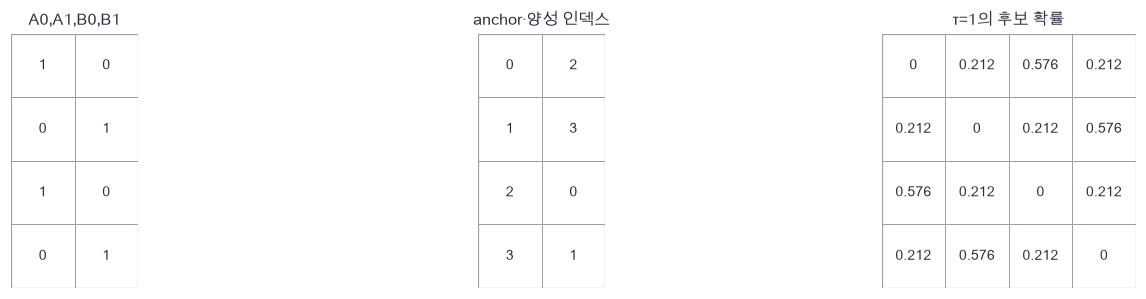

In [10]:
plot_panels([demo_u,demo_map,demo_p],['A0,A1,B0,B1','anchor·양성 인덱스','τ=1의 후보 확률'])

🔍 **확인** · 대각선 확률은0이고 양성의 확률은 e/(e+2)입니다. 다른 과일과 특징이 비슷하면 음성이라도 높은 확률을 얻을 수 있습니다. false negative의 의미는 데이터의 과제에 달려 있습니다.

In [11]:
def nce_forward(H,tau=.2):
    """2B개 뷰의 대칭 InfoNCE. 자기 대각선 제외, 양성은 B만큼 이동합니다."""
    # 쓰는 것: normalize_rows (1절)
    U,r=normalize_rows(H)
    n=len(H)
    positive=(np.arange(n)+n//2)%n
    S=U@U.T/tau
    np.fill_diagonal(S,-np.inf)
    shifted=S-np.max(S,axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    logP=shifted-np.log(expS.sum(axis=1,keepdims=True))
    loss=-logP[np.arange(n),positive].mean()
    return loss,(U,r,P,positive,tau)

In [12]:
demo_loss,demo_cache=nce_forward(demo_u,1.)
np.testing.assert_allclose(demo_cache[2],demo_p,atol=1e-8)  # 검산: 직접 계산 그림 = 구현
np.testing.assert_allclose(demo_loss,-np.log(hand_probability),atol=1e-8)  # 검산: 독립 손계산 양성 확률
single_loss,_=nce_forward(np.array([[1.,2.],[2.,1.]]),.2)
np.testing.assert_allclose(single_loss,0.)  # 검산: B=1에는 음성이 없음
print('짝 매칭·대각선 제외·B=1을 확인했습니다.')

짝 매칭·대각선 제외·B=1을 확인했습니다.


### ✏️ 연습 2 · 두 뷰의 짝 인덱스

A 다음 B 순서로 쌓인 2B개 행의 양성 인덱스를 반환하세요.

In [13]:
def exercise_positive(B):
    """A 다음 B 순서로 쌓인 2B개 행의 양성 인덱스를 반환하세요."""

    ### 구현할 내용: A 다음 B 순서로 쌓인 2B개 행의 양성 인덱스를 반환하세요.
    raise NotImplementedError
    return idx

In [14]:
def check_positive(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(3),[3,4,5,0,1,2])  # 검산: A0↔B0, A1↔B1, A2↔B2
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_positive,exercise_positive,hint="A 다음 B 순서로 쌓인 2B개 행의 양성 인덱스를 반환하세요.")

☐ exercise_positive: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: A 다음 B 순서로 쌓인 2B개 행의 양성 인덱스를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
idx = (np.arange(2*B)+B)%(2*B)
```

</details>

## 🔑 3. 점수표의 양쪽 경로를 모두 미분합니다

**이 절에서 가져갈 것:** 표현은 anchor와 후보 양쪽에 쓰여 (G+Gᵀ)가 필요합니다.

한 과일의 표현을 바꾸면 그 과일의 행뿐 아니라 모든 다른 행에서 그 과일을 보는 열도 바뀝니다. 이 둘을 더합니다.

$$G_{ij}=\frac{P_{ij}-1[j=p(i)]}{2B},\quad d_U=(G+G^T)U/\tau,$$
$$d_{Z_i}=\frac{d_{U_i}-U_i(U_i^Td_{U_i})}{r_i}.$$

이 식은 위의 epsilon 포함 r에도 그대로 맞습니다. 표현기는 $H=\tanh(XW+b)$, $Z=HV+c$입니다. $d_H=d_ZV^T$, $d_A=d_H\odot(1-H^2)$, $d_W=X^Td_A$, $d_b=\sum d_A$, $d_V=H^Td_Z$, $d_c=\sum d_Z$, $d_X=d_AW^T$입니다. 두 뷰를 한 배치로 쌓아 공유 파라미터 기여를 합합니다. 모든 파라미터와 양쪽 입력의 전 원소를 중심차분합니다.

In [15]:
# 쓰는 것: demo_p (2절) · demo_u (2절) · positive (2절)
demo_g=demo_p.copy()
demo_g[np.arange(4),positive]-=1
demo_g/=4
anchor_path=demo_g@demo_u
candidate_path=demo_g.T@demo_u
both_paths=anchor_path+candidate_path

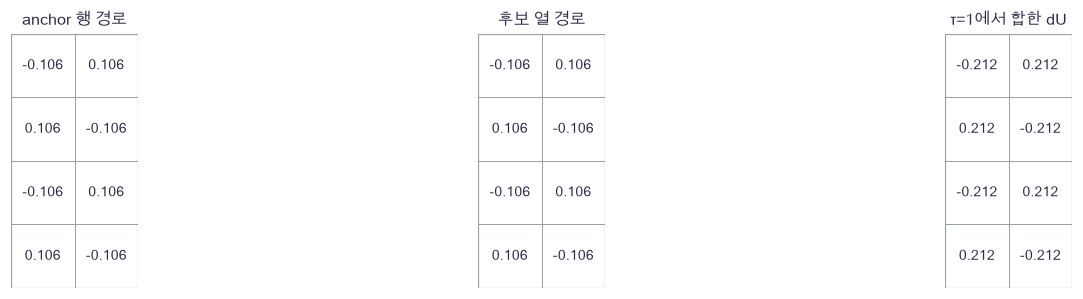

In [16]:
plot_panels([anchor_path,candidate_path,both_paths],['anchor 행 경로','후보 열 경로','τ=1에서 합한 dU'])

🔍 **확인** · 그림의 두 경로는 이 대칭 예시에서는 같지만, 일반적으로 각각 계산해야 합니다. 정규화 미분은 이 합 뒤에 적용합니다.

In [17]:
def nce_backward(cache):
    """양방향 유사도 경로와 행 정규화의 전체 미분. → dH:(2B,D)."""
    U,r,P,positive,tau=cache
    G=P.copy()
    G[np.arange(len(U)),positive]-=1
    G/=len(U)
    dU=(G+G.T)@U/tau
    dH=(dU-U*(dU*U).sum(axis=1,keepdims=True))/r
    return dH

In [18]:
def init_encoder(seed=390,hidden=8,out=3):
    """4→H→D tanh 표현기. 마지막 출력은 정규화 전 실수입니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(4,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.3,(hidden,out)),'c':np.zeros(out)}

In [19]:
def encode(X,p):
    """H=tanh(XW+b), Z=HV+c. X:(N,4) → Z:(N,D), cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [20]:
def encode_backward(dZ,cache,p):
    """공유 표현기 모든 파라미터와 연속 입력의 미분입니다."""
    X,H=cache
    dU=(dZ@p['V'].T)*(1-H**2)
    grads={'V':H.T@dZ,'c':dZ.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [21]:
# 쓰는 것: nce_backward (3절) · nce_forward (2절)
probe=init_encoder(397,hidden=3,out=2)
probe_x=np.random.default_rng(398).normal(size=(4,4))
probe_z,probe_cache=encode(probe_x,probe)
_,probe_nce=nce_forward(probe_z,.7)
analytic,analytic_x=encode_backward(nce_backward(probe_nce),probe_cache,probe)

In [22]:
def probe_objective():
    """네 뷰의 전체 표현기와 NCE를 함께 중심차분합니다."""
    # 쓰는 것: nce_forward (2절)
    Z,_=encode(probe_x,probe)
    return nce_forward(Z,.7)[0]

In [23]:
errors=[]
for name in probe:
    numeric=numerical_gradient(probe_objective,probe[name])
    np.testing.assert_allclose(analytic[name],numeric,atol=2e-7,rtol=3e-5)  # 검산: 모든 파라미터·공유 경로
    errors.append(rel_error(analytic[name],numeric))
numeric_x=numerical_gradient(probe_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-7,rtol=3e-5)  # 검산: 양쪽 뷰 입력 전체
print('전체 미분 최대 상대오차',max(errors+[rel_error(analytic_x,numeric_x)]))

전체 미분 최대 상대오차 3.7544267722323455e-10


In [24]:
# 쓰는 것: nce_backward (3절) · nce_forward (2절)
collapsed=np.ones((6,3))
collapse_loss,collapse_cache=nce_forward(collapsed,.2)
np.testing.assert_allclose(collapse_loss,np.log(5.))  # 검산: 모두 같으면 후보 다섯 개 균등
np.testing.assert_allclose(nce_backward(collapse_cache),0.,atol=1e-12)  # 검산: 정확히 상수인 대칭점은 정지점
_,single_cache=nce_forward(np.array([[1.,2.],[2.,1.]]))
np.testing.assert_allclose(nce_backward(single_cache),0.,atol=1e-12)  # 검산: B=1의 신호0
print('상수 표현의 균등 손실과 정지점을 확인했습니다.')

상수 표현의 균등 손실과 정지점을 확인했습니다.


### ✏️ 연습 3 · anchor·후보 미분 합치기

S=U@U.T/tau의 두 경로를 모두 합하세요.

In [25]:
def exercise_both_paths(G,U,tau):
    """S=U@U.T/tau의 두 경로를 모두 합하세요."""

    ### 구현할 내용: S=U@U.T/tau의 두 경로를 모두 합하세요.
    raise NotImplementedError
    return dU

In [26]:
def check_both_paths(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[0.,1.],[2.,0.]]),np.eye(2),.5),[[0.,6.],[6.,0.]])  # 검산: (G+Gᵀ)/.5
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_both_paths,exercise_both_paths,hint="S=U@U.T/tau의 두 경로를 모두 합하세요.")

☐ exercise_both_paths: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: S=U@U.T/tau의 두 경로를 모두 합하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dU = (G+G.T)@U/tau
```

</details>

## 🔑 4. 라벨 없이 실제 표현기를 학습합니다

**이 절에서 가져갈 것:** 같은 원본 두 뷰와 고정 검증 배치만으로 표현 목적을 학습합니다.

세 품종의 과일을 상태 평면의 세 군집으로 만듭니다. 관측의 앞 두 열은 상태이고 뒤 두 열은 독립 촬영 배경입니다. 두 뷰는 상태를 그대로 두고 배경만 새로 뽑습니다. 품종 라벨은 이 절의 학습 함수에 전달하지 않습니다.

> **용어** · **검증(validation)**은 학습에 쓰지 않은 원본에서 만든 고정 뷰 쌍을 관찰하는 단계입니다. 같은 배치·같은 τ로 비교해야 InfoNCE 값의 의미가 유지됩니다.

고정 계획: train512(seed391), valid32(seed392), test256(seed393), encoder seed390, 학습 난수394. 4→8→3 tanh encoder, τ=.2, 원본 B32, 250갱신, Adam lr.01. 매 스텝 원본은 비복원추출하여 같은 인덱스의 우연한 중복 음성을 피합니다. 같은 품종인 다른 과일은 여전히 음성입니다. validation으로 모델·스텝을 선택하지 않으며 test를 본 뒤 설정을 바꾸지 않습니다.

Adam의 m=.9m+.1g, v=.999v+.001g²를 bias 보정하고 $\theta\leftarrow\theta-.01\hat m/(\sqrt{\hat v}+10^{-8})$로 갱신합니다.

> **코드** · `choice(N,32,replace=False)`는 같은 스텝에서 원본 중복을 막습니다. `concatenate([A,B],axis=0)`는 뷰를 행 방향으로 쌓습니다. `X[:,2:]`는 배경 두 열입니다. `dict.items()` 반복과 `.copy()`는 초기 파라미터를 보존합니다.

In [27]:
state_preview=np.array([[1.,0.],[-.5,.866],[-.5,-.866]])
view_preview_a=np.concatenate([state_preview,np.array([[1.,0.],[0.,1.],[-1.,0.]])],axis=1)
view_preview_b=np.concatenate([state_preview,np.array([[0.,-1.],[1.,0.],[0.,1.]])],axis=1)
plan=np.array([[512,391],[32,392],[256,393]])

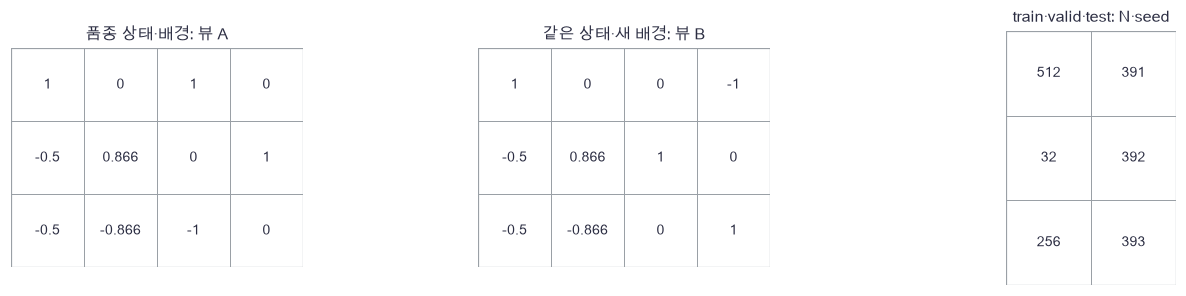

In [28]:
plot_panels([view_preview_a,view_preview_b,plan],['품종 상태·배경: 뷰 A','같은 상태·새 배경: 뷰 B','train·valid·test: N·seed'])

🔍 **확인** · 학습이 보존하도록 요청받는 것은 앞 두 열의 상태입니다. 이 합성 변형은 사람이 이미 중요한 좌표를 알고 설계한 것이며, 실제 사진의 유용한 변형을 자동 발견한 실험이 아닙니다.

In [29]:
def make_data(n,seed):
    """세 품종의 상태 2차원과 독립 배경 2차원 합성 관측을 만듭니다."""
    rng=np.random.default_rng(seed)
    y=rng.integers(0,3,n)
    angles=2*np.pi*y/3
    state=np.column_stack([np.cos(angles),np.sin(angles)])+.2*rng.normal(size=(n,2))
    nuisance=rng.normal(size=(n,2))
    return np.concatenate([state,nuisance],axis=1),y

In [30]:
def two_views(X,rng):
    """상태는 고정하고 두 뷰의 배경을 독립 재추출합니다. → (2N,4)."""
    A=X.copy()
    B=X.copy()
    A[:,2:]=rng.normal(size=(len(X),2))
    B[:,2:]=rng.normal(size=(len(X),2))
    return np.concatenate([A,B],axis=0)

In [31]:
def adam_step(p,g,m,v,step,lr=.01):
    """Adam 모멘트·bias 보정을 적용합니다."""
    for k in p:
        m[k]=.9*m[k]+.1*g[k]
        v[k]=.999*v[k]+.001*g[k]**2
        p[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)

In [32]:
def train_encoder(X,valid_views,initial):
    """라벨 없는 train 뷰로 250회 갱신하고 고정 valid 쌍에서 관찰합니다."""
    # 쓰는 것: encode (3절) · encode_backward (3절) · nce_backward (3절) · nce_forward (2절)
    # 1. 학습 난수와 독립 파라미터 사본입니다.
    p={k:a.copy() for k,a in initial.items()}
    m={k:np.zeros_like(a) for k,a in p.items()}
    v={k:np.zeros_like(a) for k,a in p.items()}
    rng=np.random.default_rng(394)
    history=[]
    # 2. 양쪽 뷰가 공유하는 파라미터에 모든 경로를 더합니다.
    for step in range(1,251):
        idx=rng.choice(len(X),32,replace=False)
        views=two_views(X[idx],rng)
        Z,cache=encode(views,p)
        loss,nce_cache=nce_forward(Z,.2)
        grads,_=encode_backward(nce_backward(nce_cache),cache,p)
        adam_step(p,grads,m,v,step)
        if step%25==0:
            valid_z,_=encode(valid_views,p)
            valid_loss,_=nce_forward(valid_z,.2)
            history.append([step,valid_loss])
    return p,np.array(history)

In [33]:
# 쓰는 것: init_encoder (3절) · make_data (4절)
train_x,train_y=make_data(512,391)
valid_x,valid_y=make_data(32,392)
test_x,test_y=make_data(256,393)
valid_views=two_views(valid_x,np.random.default_rng(395))
initial=init_encoder()
fitted,history=train_encoder(train_x,valid_views,initial)
print('파라미터',sum(a.size for a in fitted.values()),'· 250갱신·각 스텝64뷰')

파라미터 67 · 250갱신·각 스텝64뷰


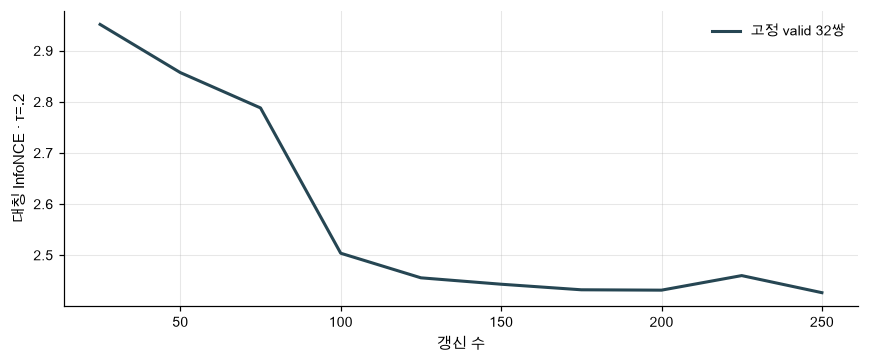

In [34]:
plot_curves([history],['고정 valid 32쌍'],'대칭 InfoNCE · τ=.2')

In [35]:
# 쓰는 것: encode (3절) · init_encoder (3절) · nce_forward (2절)
initial_z,_=encode(valid_views,initial)
fitted_z,_=encode(valid_views,fitted)
print('같은 valid 쌍: 초기/학습후',nce_forward(initial_z)[0],nce_forward(fitted_z)[0])
np.testing.assert_array_equal(initial['W'],init_encoder()['W'])  # 검산: 초기 모델 불변
assert np.isfinite(fitted_z).all(), '학습 표현이 유한해야 합니다'

같은 valid 쌍: 초기/학습후 4.77279987558402 2.4268331217215757


### ✏️ 연습 4 · 후보 개수의 기준값

모든 후보 점수가 같을 때 대칭 InfoNCE 기준 손실을 반환하세요.

In [36]:
def exercise_negative_count(B):
    """모든 후보 점수가 같을 때 대칭 InfoNCE 기준 손실을 반환하세요."""

    ### 구현할 내용: 모든 후보 점수가 같을 때 대칭 InfoNCE 기준 손실을 반환하세요.
    raise NotImplementedError
    return baseline

In [37]:
def check_negative_count(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(1),0.)  # 검산: 양성만 한 개
    np.testing.assert_allclose(candidate(3),np.log(5.))  # 검산: 양성 포함 후보 다섯 개
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_negative_count,exercise_negative_count,hint="모든 후보 점수가 같을 때 대칭 InfoNCE 기준 손실을 반환하세요.")

☐ exercise_negative_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 모든 후보 점수가 같을 때 대칭 InfoNCE 기준 손실을 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
baseline = np.log(2*B-1)
```

</details>

## 🔑 5. 고정 표현 위의 선형 평가를 따로 합니다

**이 절에서 가져갈 것:** 표현을 고정하고 학습한 probe의 독립 정확도와 표현 통계를 함께 봅니다.

표현 목적이 작아졌다고 품종을 잘 구분한다고 결론 내리지 않습니다. train 라벨로 작은 선형 분류기만 학습하고 test 품종을 맞혀 봅니다. 초기 표현기도 같은 절차로 평가합니다.

> **용어** · **선형 probe**는 표현기를 고정하고 $R=UW_q+b_q$만 학습하는 분류기입니다. **동결(freeze)**은 encoder 파라미터를 갱신하지 않는다는 뜻입니다. **표현 분산**은 관측 축에서 각 특징이 얼마나 달라지는지입니다.

$U:(N,3)$의 정규화 표현에서 3클래스 CE를 씁니다. $G=(\operatorname{softmax}R-\mathrm{onehot}(y))/N$, $dW_q=U^TG$, $db_q=\sum G$입니다. train512개 전배치,0초기값, SGD lr.15,300갱신을 두 표현에 똑같이 적용합니다. test 정확도 분모는256관측이며 3클래스 동률은 `argmax`의 첫 인덱스입니다. probe 기울기는 encoder로 전파하지 않습니다. 초기·학습 후 모두 전체 특징의 평균·분산, 양성 거리, 독립 test 정확도를 보고합니다. 한 학습 seed의 작은 실험이므로 일반적인 성능 우위를 주장하지 않습니다.

In [38]:
probe_features=np.array([[1.,0.],[0.,1.],[-1.,0.]])
probe_weights=np.array([[1.,-1.,0.],[0.,1.,-1.]])
probe_scores=probe_features@probe_weights
probe_prob=np.exp(probe_scores-probe_scores.max(axis=1,keepdims=True))
probe_prob/=probe_prob.sum(axis=1,keepdims=True)

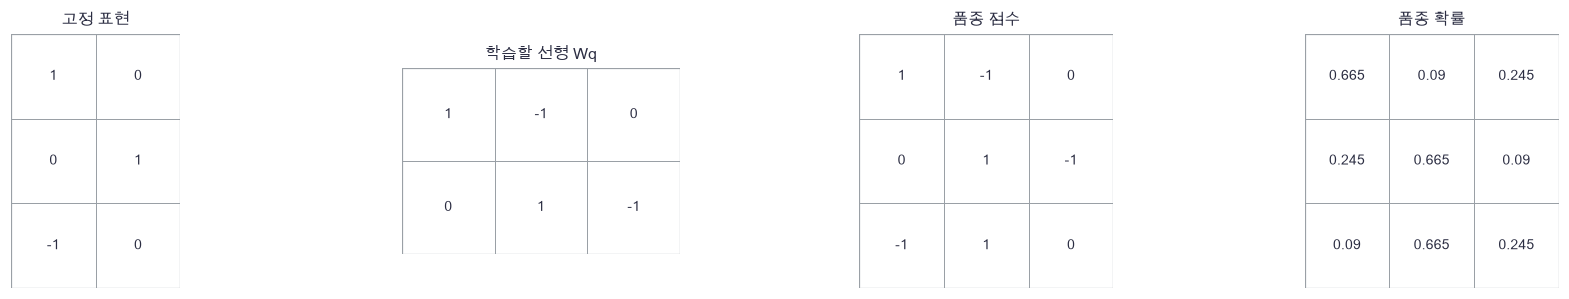

In [39]:
plot_panels([probe_features,probe_weights,probe_scores,probe_prob],['고정 표현','학습할 선형 Wq','품종 점수','품종 확률'])

🔍 **확인** · 고정 표현을 바꾸지 않고 품종 점수표만 학습합니다. 그림은 작은 직접 계산이며 아래의 실제 학습 결과와 구별합니다.

In [40]:
def multiclass_loss(logits,y):
    """안정적인 표본 평균 CE와 logit 미분. (N,C), (N,) → scalar,(N,C)."""
    shifted=logits-logits.max(axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    loss=np.mean(np.log(expS.sum(axis=1))-shifted[np.arange(len(y)),y])
    G=P.copy()
    G[np.arange(len(y)),y]-=1
    return loss,G/len(y)

In [41]:
def fit_probe(features,y):
    """고정 표현 위의 선형 3클래스 probe만 300회 전배치 SGD 학습합니다."""
    W=np.zeros((features.shape[1],3))
    b=np.zeros(3)
    for step in range(300):
        loss,G=multiclass_loss(features@W+b,y)
        W-=.15*features.T@G
        b-=.15*G.sum(axis=0)
    return W,b

In [42]:
probe_check_x=np.array([[1.,2.],[-1.,.5]])
probe_check_y=np.array([0,2])
probe_check_w=np.array([[.2,-.1,.3],[.1,.4,-.2]])
_,probe_check_g=multiclass_loss(probe_check_x@probe_check_w,probe_check_y)
probe_analytic=probe_check_x.T@probe_check_g

In [43]:
def linear_objective():
    """선형 probe CE의 가중치 미분을 독립 검산합니다."""
    return multiclass_loss(probe_check_x@probe_check_w,probe_check_y)[0]

In [44]:
np.testing.assert_allclose(probe_analytic,numerical_gradient(linear_objective,probe_check_w),atol=1e-8)  # 검산: probe 가중치 중심차분
print('선형 probe CE 미분을 확인했습니다.')

선형 probe CE 미분을 확인했습니다.


In [45]:
# 쓰는 것: encode (3절) · fit_probe (5절) · fitted (4절) · initial (4절) · normalize_rows (1절) · test_x (4절) · test_y (4절) · train_x (4절) · train_y (4절) · valid_views (4절)
summary=[]
representations=[]
for p in [initial,fitted]:
    before={k:a.copy() for k,a in p.items()}
    train_z,_=encode(train_x,p)
    train_u,_=normalize_rows(train_z)
    test_z,_=encode(test_x,p)
    test_u,_=normalize_rows(test_z)
    qw,qb=fit_probe(train_u,train_y)
    accuracy=np.mean((test_u@qw+qb).argmax(axis=1)==test_y)
    pair_z,_=encode(valid_views,p)
    pair_u,_=normalize_rows(pair_z)
    distance=((pair_u[:32]-pair_u[32:])**2).sum(axis=1).mean()
    summary.append([accuracy,test_u.mean(),test_u.var(axis=0).mean(),distance])
    representations.append(test_u)
    for key in p:
        np.testing.assert_array_equal(p[key],before[key])  # 검산: probe 학습 중 encoder 불변
summary=np.array(summary)
print('초기/학습후: test 정확도·표현 평균·평균분산·valid 양성거리',np.round(summary,4))

초기/학습후: test 정확도·표현 평균·평균분산·valid 양성거리 [[ 0.7539 -0.0051  0.3321  0.9511]
 [ 0.957   0.0615  0.304   0.0042]]


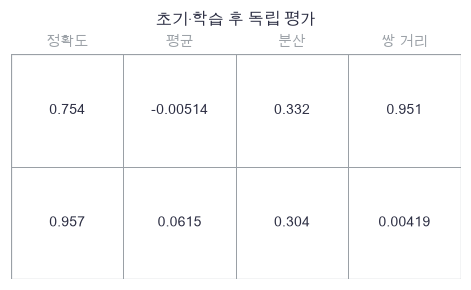

In [46]:
plot_panels([summary],['초기·학습 후 독립 평가'],[['정확도','평균','분산','쌍 거리']])

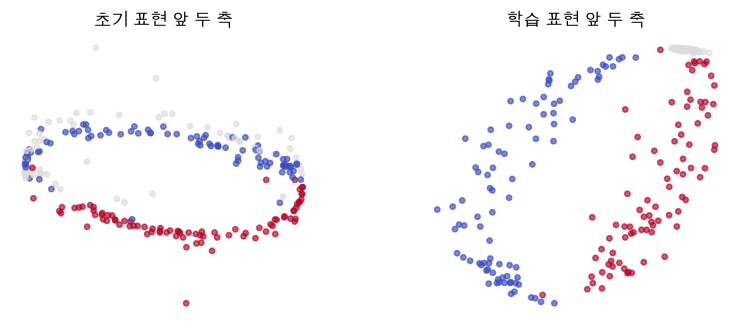

In [47]:
plot_points([u[:,:2] for u in representations],[test_y,test_y],['초기 표현 앞 두 축','학습 표현 앞 두 축'])

🔍 **확인** · 두 축 그림은 3차원 표현의 일부만 보입니다. 평균이0에 가깝거나 분산이 크다는 것만으로 품종 정보가 증명되지는 않습니다. test 정확도는 독립 분할의 특정 선형 평가이고, 목적값과 양성 거리는 다른 질문에 답합니다. B·τ·음성 구성 비교를 추가한다면 새 고정 계획과 새 test를 준비하세요.

### ✏️ 연습 5 · 선형 probe의 출력 축

고정 표현에서 관측별 클래스 인덱스를 반환하세요.

In [48]:
def exercise_probe_prediction(U,W,bias):
    """고정 표현에서 관측별 클래스 인덱스를 반환하세요."""

    ### 구현할 내용: 고정 표현에서 관측별 클래스 인덱스를 반환하세요.
    raise NotImplementedError
    return prediction

In [49]:
def check_probe_prediction(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.eye(2),np.array([[0.,3.,1.],[4.,0.,2.]]),np.zeros(3)),[1,0])  # 검산: 행마다 최대 클래스
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_probe_prediction,exercise_probe_prediction,hint="고정 표현에서 관측별 클래스 인덱스를 반환하세요.")

☐ exercise_probe_prediction: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 고정 표현에서 관측별 클래스 인덱스를 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
prediction = (U@W+bias).argmax(axis=1)
```

</details>

## ✏️ 끝 연습 · 후보·분모·배치 대응을 바꿔 봅니다

### ✏️ 연습 A · 두 후보의 온도

한 행의 두 후보 점수에 온도를 적용하고 확률로 만드세요.

In [50]:
def exercise_temperature(scores,tau):
    """한 행의 두 후보 점수에 온도를 적용하고 확률로 만드세요."""

    ### 구현할 내용: 한 행의 두 후보 점수에 온도를 적용하고 확률로 만드세요.
    raise NotImplementedError
    return P

In [51]:
def check_temperature(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([0.,np.log(3.)]),1.),[.25,.75])  # 검산: 지수비1:3
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_temperature,exercise_temperature,hint="한 행의 두 후보 점수에 온도를 적용하고 확률로 만드세요.")

☐ exercise_temperature: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 한 행의 두 후보 점수에 온도를 적용하고 확률로 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
E = np.exp((scores-scores.max())/tau)
P = E/E.sum()
```

</details>

### ✏️ 연습 B · 자기 자신 확률 제외

지수 점수표 E를 복사한 뒤 자기 자신 위치만0으로 만드세요.

In [52]:
def exercise_masked_diagonal(E):
    """지수 점수표 E를 복사한 뒤 자기 자신 위치만0으로 만드세요."""
    masked = E.copy()
    ### 구현할 내용: 지수 점수표 E를 복사한 뒤 자기 자신 위치만0으로 만드세요.
    raise NotImplementedError
    return masked

In [53]:
def check_masked_diagonal(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.ones((3,3))),np.ones((3,3))-np.eye(3))  # 검산: 대각선만0
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_masked_diagonal,exercise_masked_diagonal,hint="지수 점수표 E를 복사한 뒤 자기 자신 위치만0으로 만드세요.")

☐ exercise_masked_diagonal: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 지수 점수표 E를 복사한 뒤 자기 자신 위치만0으로 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
np.fill_diagonal(masked,0.)
```

</details>

### ✏️ 연습 C · 정답 위치를 빼는 CE 기울기

양성 인덱스 onehot을 빼고 anchor 수로 평균하세요.

In [54]:
def exercise_contrastive_grad(P,positive):
    """양성 인덱스 onehot을 빼고 anchor 수로 평균하세요."""
    G = P.copy()
    ### 구현할 내용: 양성 인덱스 onehot을 빼고 anchor 수로 평균하세요.
    raise NotImplementedError
    return G

In [55]:
def check_contrastive_grad(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[.2,.8],[.7,.3]]),np.array([1,0])),[[.1,-.1],[-.15,.15]])  # 검산: 표본 둘의 평균
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_contrastive_grad,exercise_contrastive_grad,hint="양성 인덱스 onehot을 빼고 anchor 수로 평균하세요.")

☐ exercise_contrastive_grad: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 양성 인덱스 onehot을 빼고 anchor 수로 평균하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
G[np.arange(len(P)),positive] -= 1
G /= len(P)
```

</details>

### ✏️ 연습 D · 두 뷰의 같은 원본 순열

두 뷰를 같은 순열로 바꾸고 A 다음 B로 쌓아 양성 offset을 유지하세요.

In [56]:
def exercise_joint_permutation(A,B,order):
    """두 뷰를 같은 순열로 바꾸고 A 다음 B로 쌓아 양성 offset을 유지하세요."""

    ### 구현할 내용: 두 뷰를 같은 순열로 바꾸고 A 다음 B로 쌓아 양성 offset을 유지하세요.
    raise NotImplementedError
    return views

In [57]:
def check_joint_permutation(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[10.],[20.],[30.]]),np.array([[11.],[21.],[31.]]),np.array([2,0,1])),[[30.],[10.],[20.],[31.],[11.],[21.]])  # 검산: B=3에서도 짝 offset 유지
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_joint_permutation,exercise_joint_permutation,hint="두 뷰를 같은 순열로 바꾸고 A 다음 B로 쌓아 양성 offset을 유지하세요.")

☐ exercise_joint_permutation: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 두 뷰를 같은 순열로 바꾸고 A 다음 B로 쌓아 양성 offset을 유지하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
views = np.concatenate([A[order],B[order]],axis=0)
```

</details>

### ✏️ 준비도 질문

- **설명:** 음성 후보가 같은 품종일 수도 있는 이유와 B=1에서 학습 신호가 사라지는 이유를 설명할 수 있나요? → 2절
- **수식:** 2B−1 분모, 양성 인덱스, 온도, (G+Gᵀ), epsilon 정규화 미분을 쓸 수 있나요? → 1–3절
- **구현:** 양쪽 뷰와 모든 파라미터의 미분을 검사하고, encoder를 고정한 probe만 갱신할 수 있나요? → 3·5절
- **변형 검산:** B·D·뷰 순서가 바뀌어도 self 제외·짝 대응·평가 분모를 확인할 수 있나요? → 연습 A–D

### 📎 원전과 다음 연결

[SimCLR 원논문, Chen et al., 2020](https://proceedings.mlr.press/v119/chen20j.html)의 두 뷰·온도·대칭 대조 목적을 작은 합성 자료에서 구현했습니다. 원논문의 영상 encoder·projection head·대규모 학습을 복제한 benchmark는 아닙니다. 여기서는 하나의 작은 표현기를 직접 정규화하며 별도 projection head를 두지 않습니다. 40번에서는 음성 대신 교사 표현을 예측할 때의 기울기 차단과 EMA를 확인합니다.